In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from scipy.cluster.hierarchy import linkage, dendrogram


In [ ]:

df = pd.read_csv('/content/Mall_Customers (1).csv')

print("Dataset loaded successfully.")
print("Shape:", df.shape)

df.head()


Dataset loaded successfully.
Shape: (200, 5)


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [ ]:

print("Column names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nMissing values:")
print(df.isnull().sum())

print("\nStatistical summary:")
df.describe()


Column names:
['CustomerID', 'Gender', 'Age', 'Annual Income (k$)', 'Spending Score (1-100)']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Gender                  200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual Income (k$)      200 non-null    int64 
 4   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB

Missing values:
CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64

Statistical summary:


,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200.000000,200.000000,200.000000
mean,100.500000,38.850000,60.560000,50.200000
std,57.879185,13.969007,26.264721,25.823522
min,1.000000,18.000000,15.000000,1.000000
25%,50.750000,28.750000,41.500000,34.750000
50%,100.500000,36.000000,61.500000,50.000000
75%,150.250000,49.000000,78.000000,73.000000
max,200.000000,70.000000,137.000000,99.000000


In [ ]:

X = df[['Annual Income (k$)', 'Spending Score (1-100)']]

print("Selected features:", X.columns.tolist())
print("Feature matrix shape:", X.shape)

X.head()


Selected features: ['Annual Income (k$)', 'Spending Score (1-100)']
Feature matrix shape: (200, 2)


,Annual Income (k$),Spending Score (1-100)
0,15,39
1,15,81
2,16,6
3,16,77
4,17,40


In [ ]:

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

print("Scaled feature matrix shape:", X_scaled.shape)
print("\nFirst five standardized records:")
print(X_scaled[:5])


Scaled feature matrix shape: (200, 2)

First five standardized records:
[[-1.73899919 -0.43480148]
 [-1.73899919  1.19570407]
 [-1.70082976 -1.71591298]
 [-1.70082976  1.04041783]
 [-1.66266033 -0.39597992]]


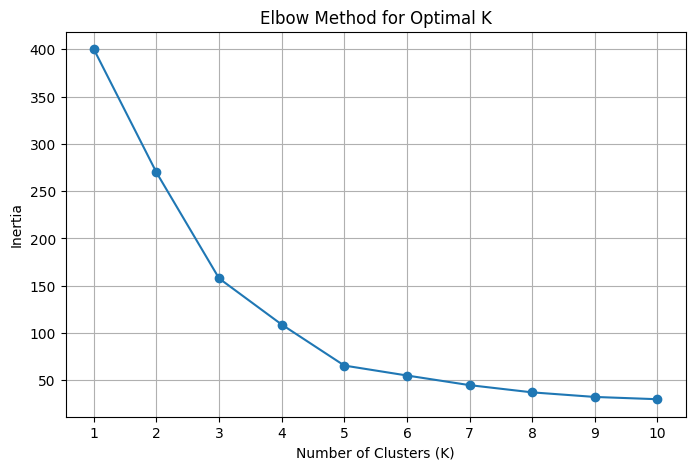

In [ ]:

inertia = []

for k in range(1, 11):
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    inertia.append(kmeans.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(range(1, 11), inertia, marker='o')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Inertia')
plt.title('Elbow Method for Optimal K')
plt.xticks(range(1, 11))
plt.grid(True)
plt.show()


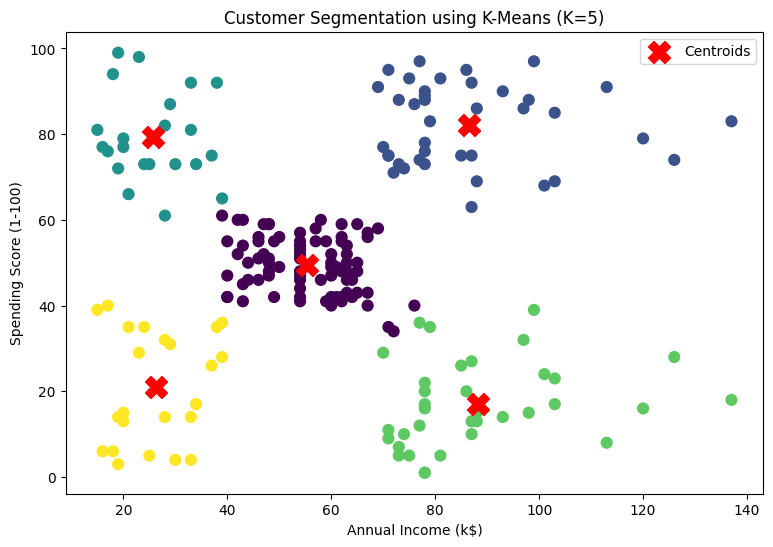

Customers in each cluster:
KMeans_Cluster
0    81
1    39
2    22
3    35
4    23
Name: count, dtype: int64


In [ ]:

kmeans = KMeans(n_clusters=5, random_state=42, n_init=10)
kmeans_labels = kmeans.fit_predict(X_scaled)

# Add cluster assignments to the original dataset
df['KMeans_Cluster'] = kmeans_labels

# Plot clusters using the original feature values
plt.figure(figsize=(9, 6))

plt.scatter(
    X['Annual Income (k$)'],
    X['Spending Score (1-100)'],
    c=kmeans_labels,
    cmap='viridis',
    s=60
)

# Convert standardized centroids back to original units
centroids = scaler.inverse_transform(kmeans.cluster_centers_)

plt.scatter(
    centroids[:, 0],
    centroids[:, 1],
    marker='X',
    s=250,
    c='red',
    label='Centroids'
)

plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')
plt.title('Customer Segmentation using K-Means (K=5)')
plt.legend()
plt.show()

print("Customers in each cluster:")
print(df['KMeans_Cluster'].value_counts().sort_index())


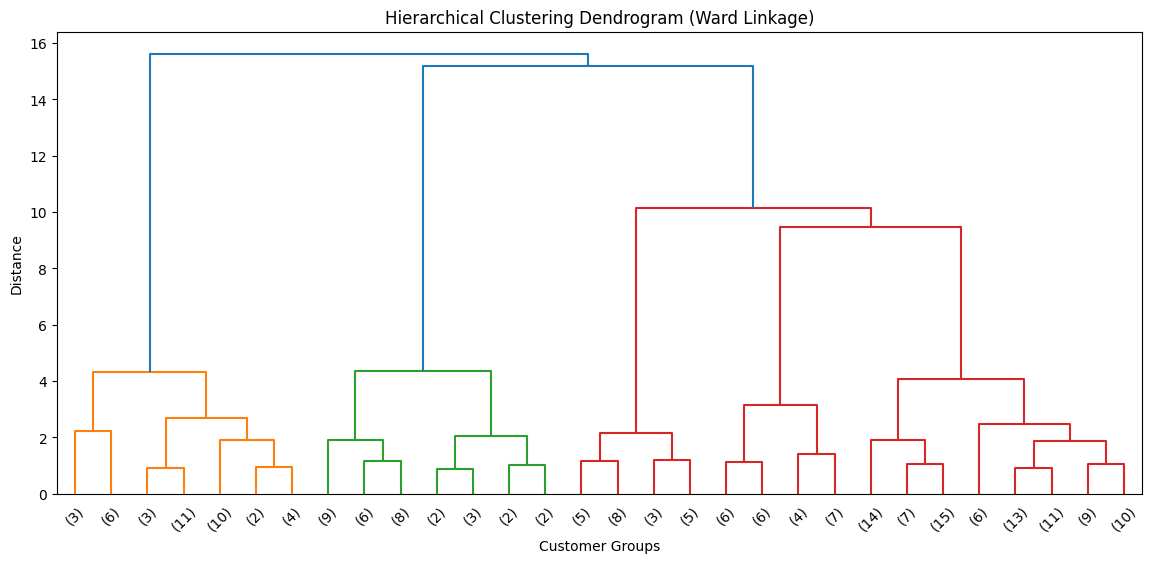

In [ ]:

# Create the hierarchical linkage matrix
Z = linkage(X_scaled, method='ward')

# Plot the dendrogram
plt.figure(figsize=(14, 6))

dendrogram(
    Z,
    truncate_mode='lastp',
    p=30,
    show_leaf_counts=True
)

plt.title('Hierarchical Clustering Dendrogram (Ward Linkage)')
plt.xlabel('Customer Groups')
plt.ylabel('Distance')
plt.show()


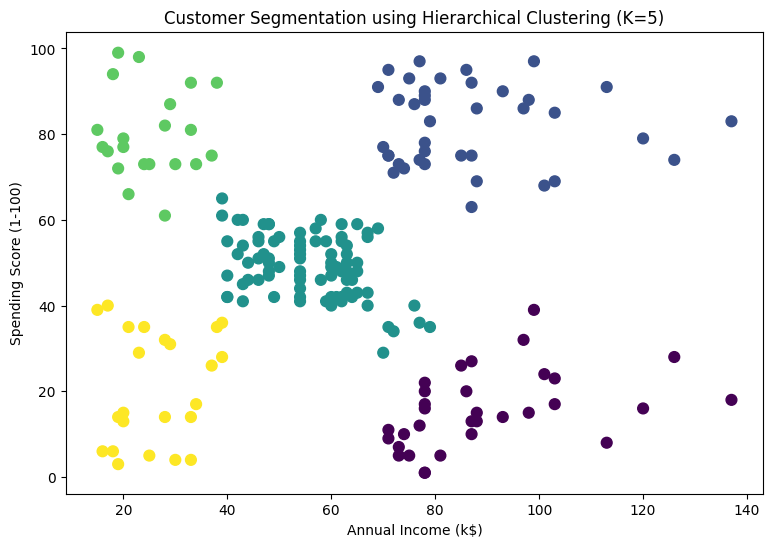

Customers in each hierarchical cluster:
Hierarchical_Cluster
0    32
1    39
2    85
3    21
4    23
Name: count, dtype: int64


In [ ]:

hierarchical = AgglomerativeClustering(
    n_clusters=5,
    linkage='ward'
)

hierarchical_labels = hierarchical.fit_predict(X_scaled)

df['Hierarchical_Cluster'] = hierarchical_labels

plt.figure(figsize=(9, 6))

plt.scatter(
    X['Annual Income (k$)'],
    X['Spending Score (1-100)'],
    c=hierarchical_labels,
    cmap='viridis',
    s=60
)

plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')
plt.title('Customer Segmentation using Hierarchical Clustering (K=5)')
plt.show()

print("Customers in each hierarchical cluster:")
print(df['Hierarchical_Cluster'].value_counts().sort_index())
